# Homework 6 - Tree-Based Methods

**USC ID:** 1450125536  
**Name:** Yufan Yao  
**GitHub:** yufanyao-cloud


## 1. APS Failure at Scania Trucks

### 1(a). Context

The response variable is class. pos indicates an APS-related failure and neg indicates otherwise. The data includes 170 numeric predictors and the supplied files already define the training and test sets.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    auc,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 552
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
data_candidates = [Path("../data"), Path("data")]
DATA_DIR = next((folder for folder in data_candidates if folder.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not locate the project data directory.") 


### 1(b)(i). Load data and handle missing values

Each APS CSV file has 20 descriptive lines before the header. I skip these lines and treat `na` as missing. I considered mean/median imputation, k-nearest-neighbor imputation, and iterative/multiple imputation. I use median imputation because the sensor variables are skewed and can contain outliers.

Following Footnote 1 in the homework handout, I calculate medians separately for the supplied training and test sets. This is the convention requested for this assignment: when filling a future test set, the training data are not assumed to be available. The output confirms that no missing values remain.

**Sources for imputation methods:** Little and Rubin, *Statistical Analysis with Missing Data* (3rd ed., 2019); van Buuren, *Flexible Imputation of Missing Data* (2nd ed., 2018).

In [2]:
def read_aps_csv(path):
    return pd.read_csv(path, skiprows=20, na_values="na")


train_raw = read_aps_csv(DATA_DIR / "aps_failure_training_set.csv")
test_raw = read_aps_csv(DATA_DIR / "aps_failure_test_set.csv")

X_train_raw = train_raw.drop(columns="class").apply(pd.to_numeric, errors="coerce")
X_test_raw = test_raw.drop(columns="class").apply(pd.to_numeric, errors="coerce")
y_train = (train_raw["class"] == "pos").astype(int)
y_test = (test_raw["class"] == "pos").astype(int)

print(f"Training shape: {X_train_raw.shape}; test shape: {X_test_raw.shape}")
print("Missing values before imputation:")
display(
    pd.DataFrame(
        {
            "train_missing": X_train_raw.isna().sum(),
            "test_missing": X_test_raw.isna().sum(),
        }
    )
    .describe()
    .T
)

train_imputer = SimpleImputer(strategy="median")
test_imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    train_imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    test_imputer.fit_transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index,
)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
print("Median imputation completed separately for training and test data.")


Training shape: (60000, 170); test shape: (16000, 170)
Missing values before imputation:


,count,mean,std,min,25%,50%,75%,max
train_missing,170.0,5000.088235,10235.739444,0.0,671.0,688.0,2727.0,49264.0
test_missing,170.0,1345.176471,2726.042569,0.0,189.0,193.0,764.0,13129.0


Median imputation completed separately for training and test data.


### 1(b)(ii). Coefficients of variation

For each predictor, I calculate the coefficient of variation exactly as defined in the homework:

CV = s / m,

where s is the sample standard deviation and m is the sample mean. Features with a zero mean are excluded because their CV is undefined.

In [3]:
feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)
cv_values = feature_stds / feature_means.replace(0, np.nan)
cv_ranking = (
    cv_values.replace([np.inf, -np.inf], np.nan).dropna().sort_values(ascending=False)
)

top_k = int(np.floor(np.sqrt(X_train.shape[1])))
top_cv_features = cv_ranking.head(top_k).index.tolist()
print(f"floor(sqrt({X_train.shape[1]})) = {top_k}")
display(cv_ranking.head(top_k).rename("CV").to_frame())


floor(sqrt(170)) = 13


,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


### 1(b)(iii). Correlation matrix

Since the full 170-variable correlation matrix is dense, I hide the tick labels so that the color pattern remains readable. The matrix itself still includes every predictor.

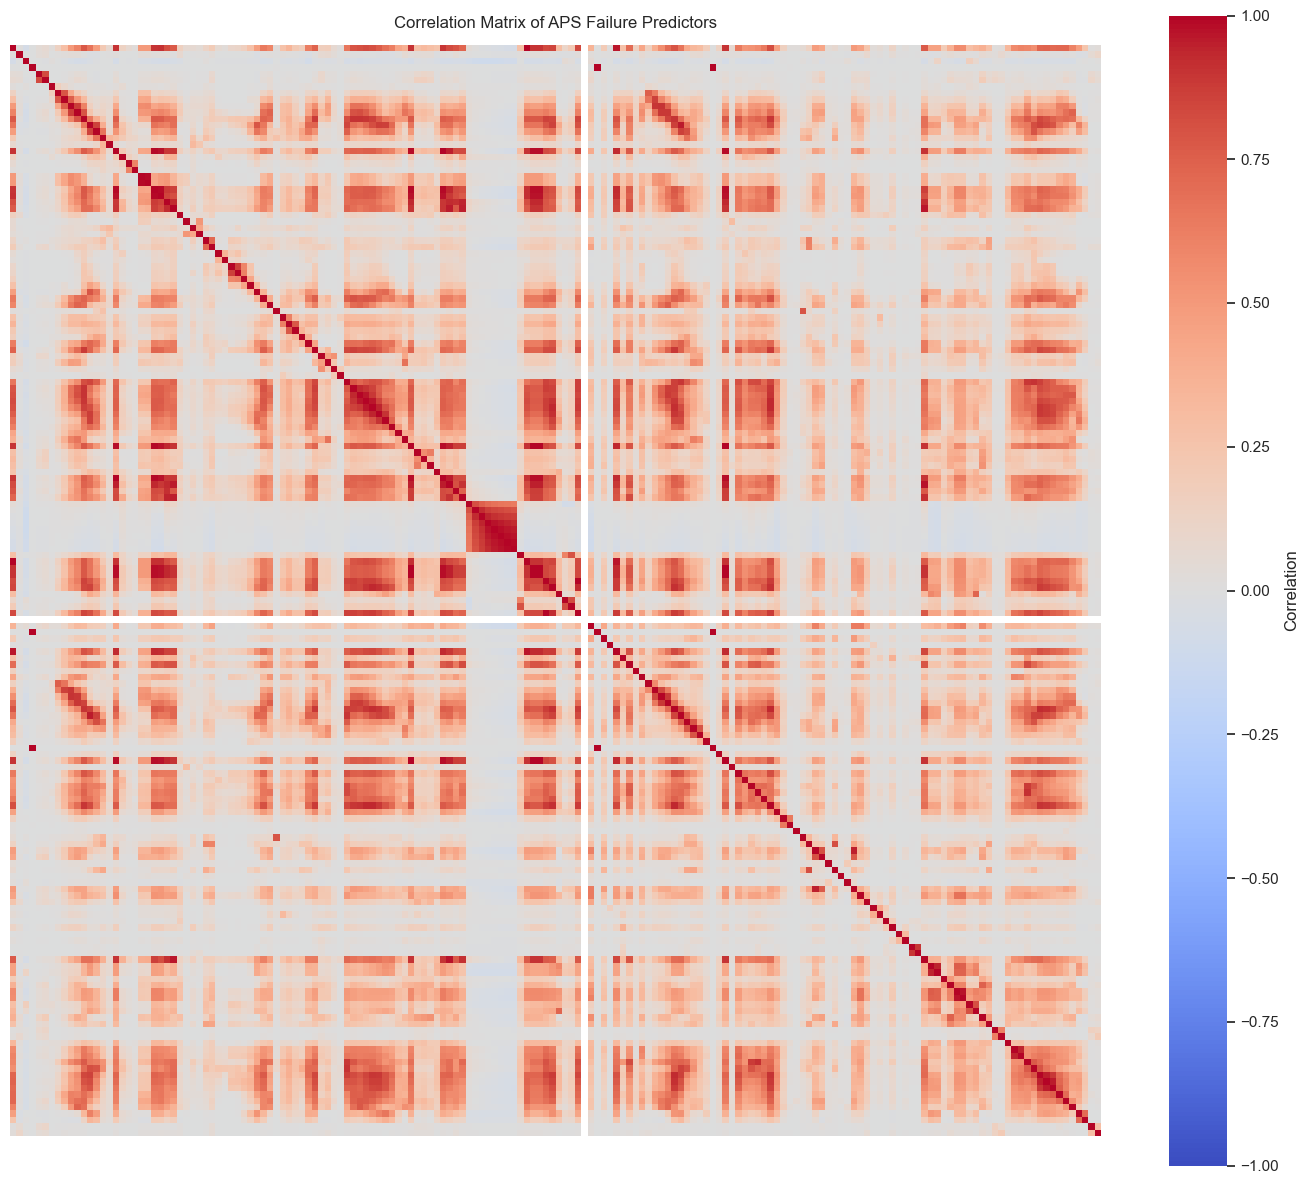

In [4]:
correlation_matrix = X_train.corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Correlation"},
    ax=ax,
)
ax.set_title("Correlation Matrix of APS Failure Predictors", pad=12)
plt.tight_layout()
plt.show()


### 1(b)(iv). Top-CV feature plots

For the predictors with the largest CV values, I compare their values across the two classes using scatter and box plots. These figures are exploratory: visible separation or outliers may be useful, but the plots alone are not enough to claim statistical significance.

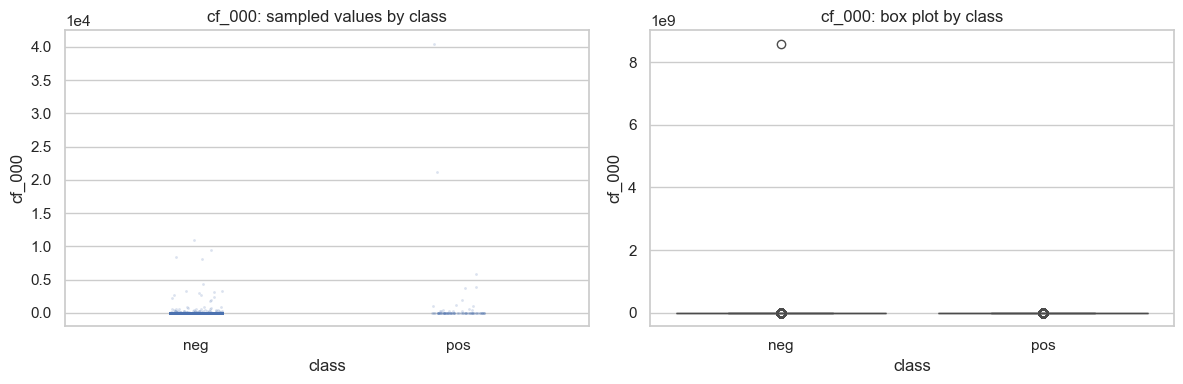

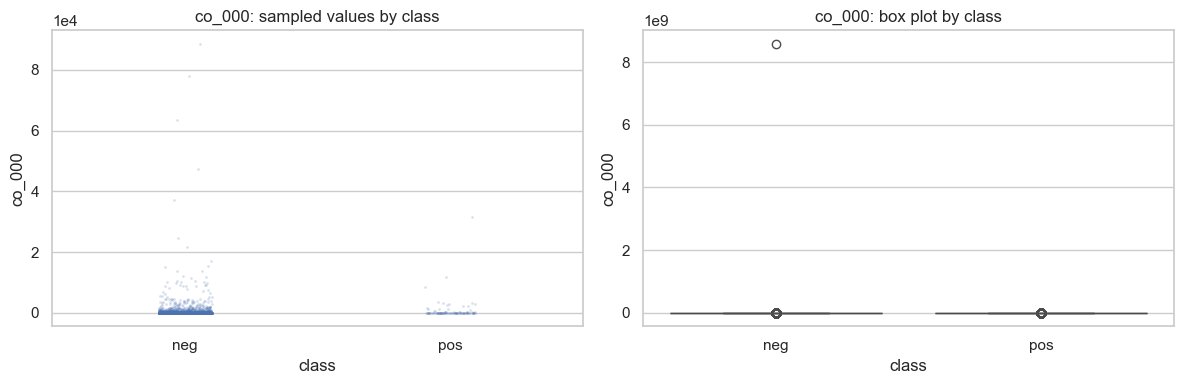

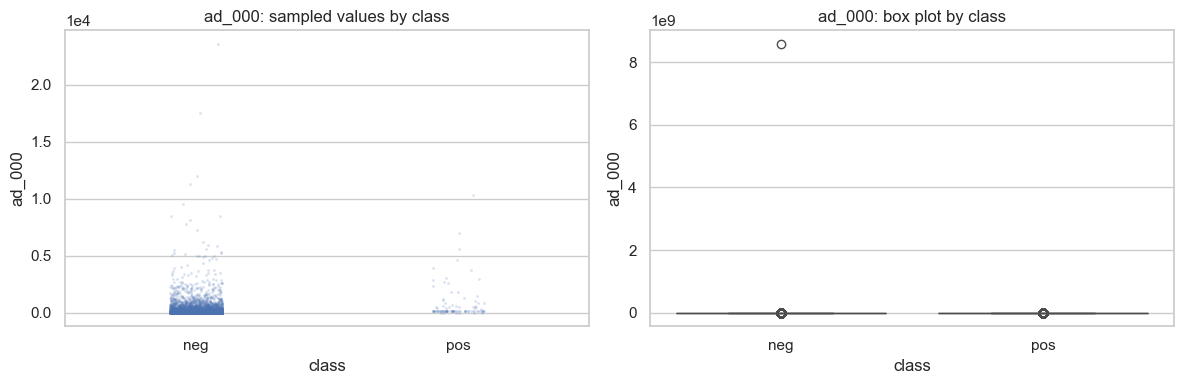

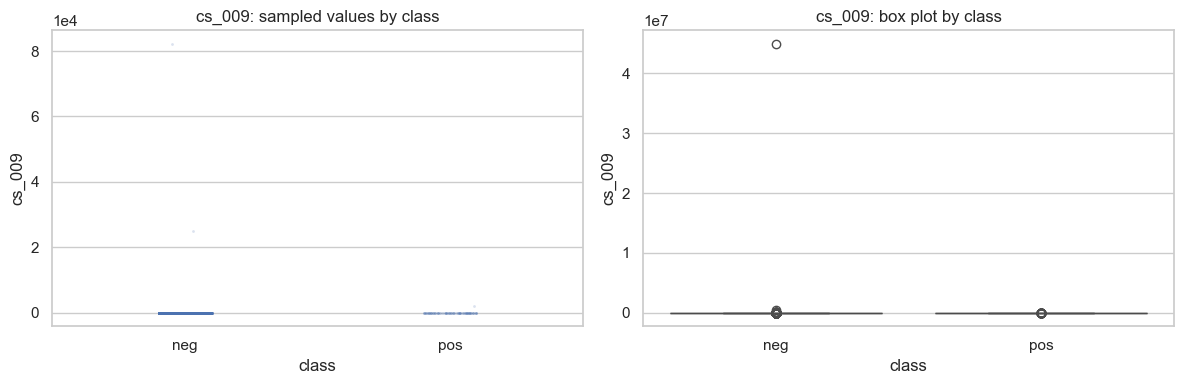

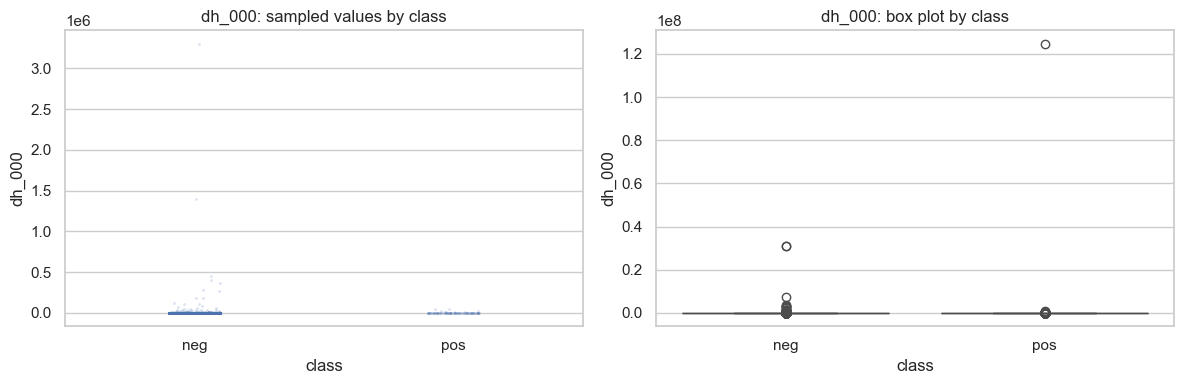

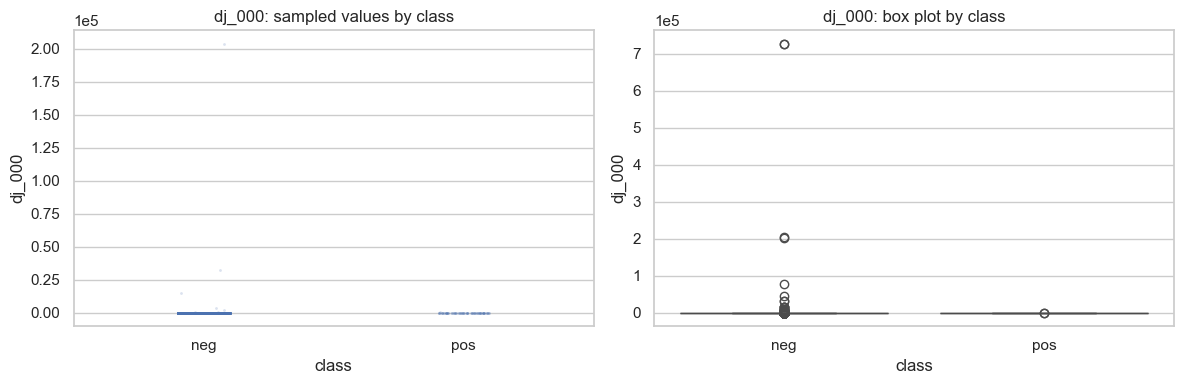

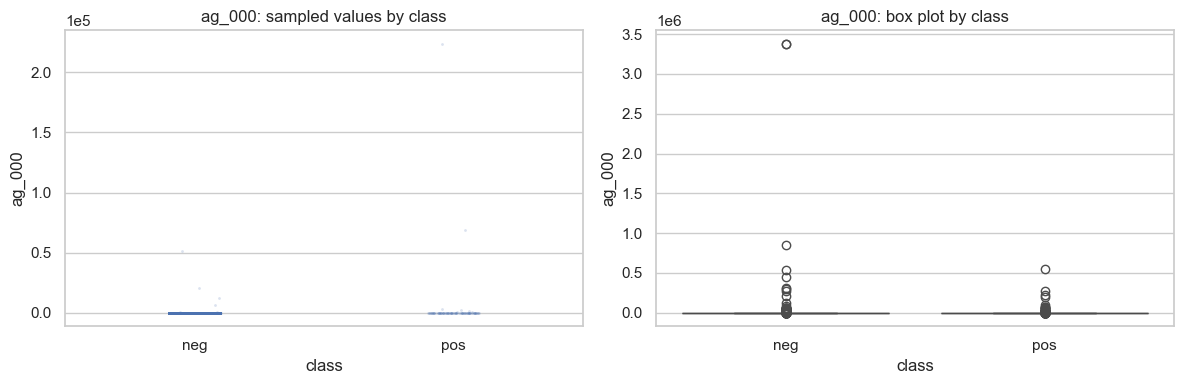

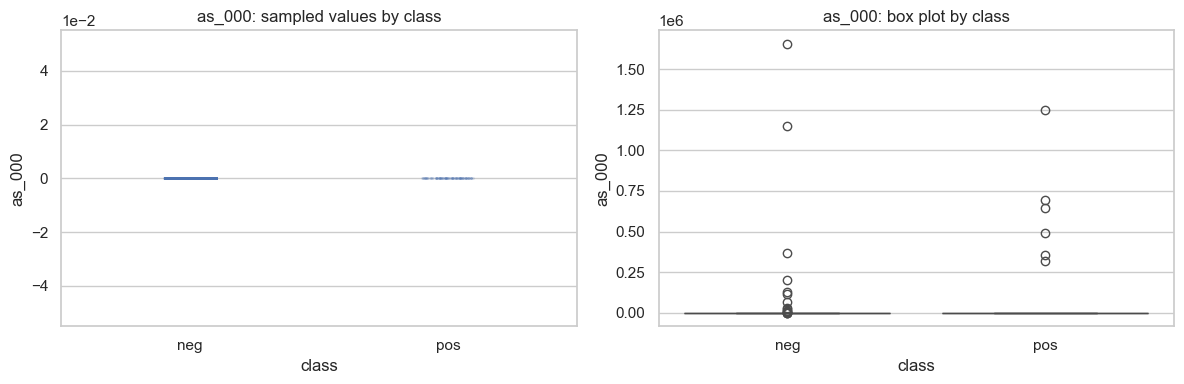

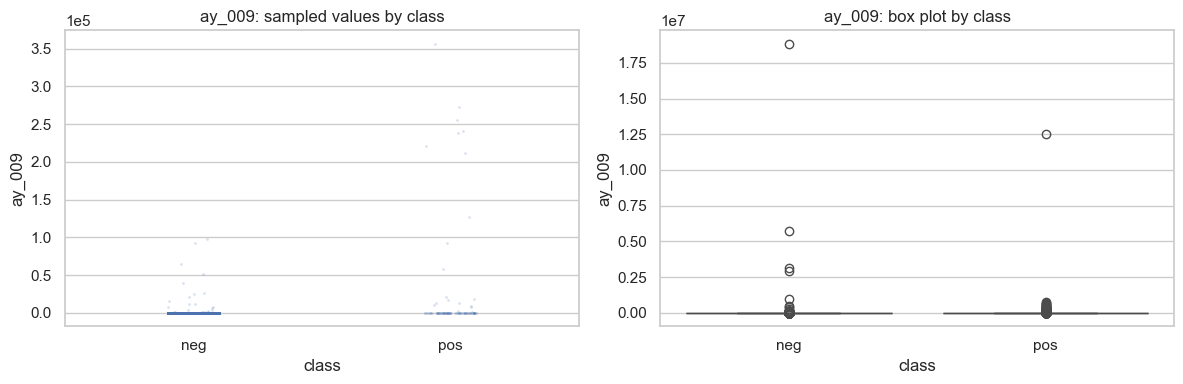

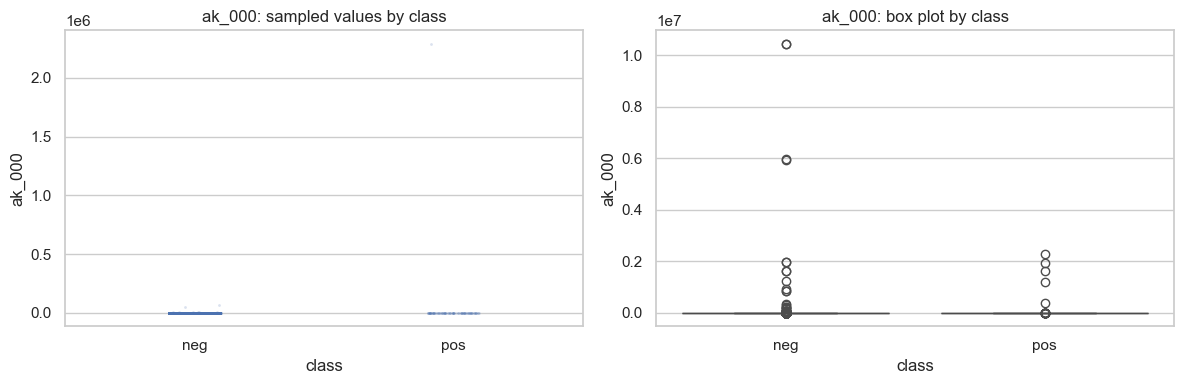

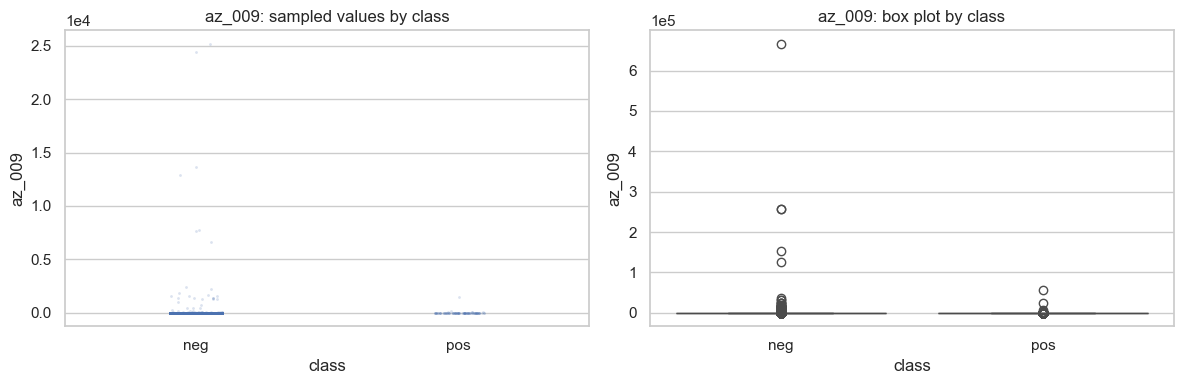

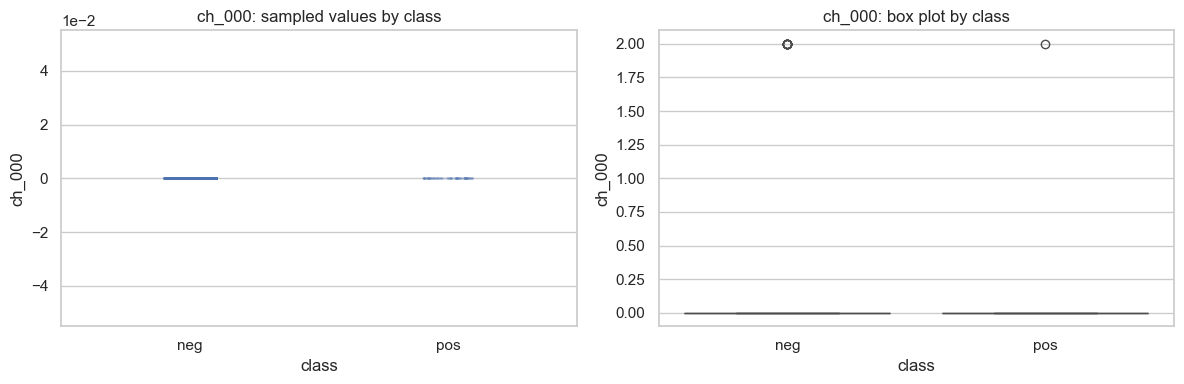

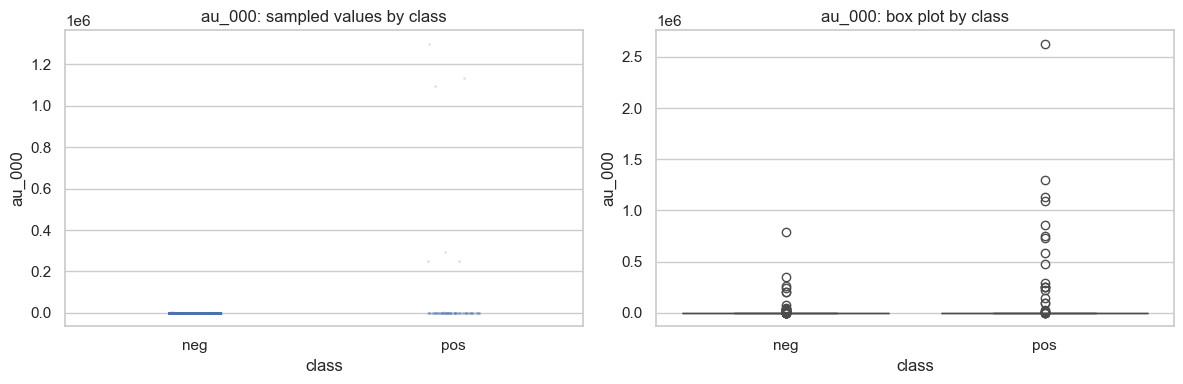

In [5]:
plot_frame = X_train[top_cv_features].copy()
plot_frame["class"] = np.where(y_train.eq(1), "pos", "neg")

for feature in top_cv_features:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sample = plot_frame[[feature, "class"]].sample(
        min(5000, len(plot_frame)), random_state=RANDOM_STATE
    )

    sns.stripplot(data=sample, x="class", y=feature, alpha=0.20, size=2, ax=axes[0])
    axes[0].set_title(f"{feature}: sampled values by class")

    sns.boxplot(data=plot_frame, x="class", y=feature, ax=axes[1])
    axes[1].set_title(f"{feature}: box plot by class")

    for axis in axes:
        axis.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

    plt.tight_layout()
    plt.show()


In [6]:
feature_evidence = pd.DataFrame({
    "mean": X_train[top_cv_features].mean(),
    "standard_deviation": X_train[top_cv_features].std(ddof=1),
    "CV": cv_ranking[top_cv_features],
    "correlation_with_class": X_train[top_cv_features].corrwith(y_train),
    "median_neg": X_train.loc[y_train.eq(0), top_cv_features].median(),
    "median_pos": X_train.loc[y_train.eq(1), top_cv_features].median(),
}).sort_values("CV", ascending=False)

display(feature_evidence.round(4))

,mean,standard_deviation,CV,correlation_with_class,median_neg,median_pos
cf_000,143107.5341,3.504525e+07,244.8875,-0.0005,2.0,2.0
co_000,143330.0177,3.504525e+07,244.5074,-0.0005,8.0,8.0
ad_000,143438.2921,3.504525e+07,244.3228,-0.0005,126.0,126.0
cs_009,770.5097,1.833278e+05,237.9306,-0.0005,0.0,0.0
dh_000,4392.6408,5.412441e+05,123.2161,0.0301,0.0,0.0
dj_000,37.2713,4.379166e+03,117.4942,-0.0011,0.0,0.0
ag_000,219.1577,2.036364e+04,92.9178,0.0124,0.0,0.0
as_000,125.4079,1.095219e+04,87.3325,0.0431,0.0,0.0
ay_009,1149.6196,9.741156e+04,84.7337,0.0423,0.0,0.0
ak_000,907.6607,7.299859e+04,80.4250,0.0118,0.0,0.0


### 1(b)(iv). Written answer

I selected these 13 predictors because they have the largest coefficients of variation, as required. The evidence table reports each predictor's standard deviation, CV, correlation with the binary class label, and class-specific medians. Together with the scatter and box plots, these values show whether a selected predictor has different typical values across `neg` and `pos` observations. This supports the exploratory feature selection, but it is not a confidence-interval or hypothesis-test result; I therefore do not claim statistical significance from these plots alone.

### 1(b)(v). Class imbalance

I count the positive and negative observations in both data sets. Because the positive class is rare, accuracy by itself can be misleading. I therefore also report ROC-AUC, ROC curves, and confusion matrices below.

The executed counts show a severe imbalance: the training data has 1,000 positive observations out of 60,000 (1.67%), and the test data has 375 positives out of 16,000 (2.34%). This is why I compare confusion matrices and ROC-AUC rather than relying only on accuracy.

,train,test
neg,59000,15625
pos,1000,375


,train_percent,test_percent
class,,
neg,98.33,97.66
pos,1.67,2.34


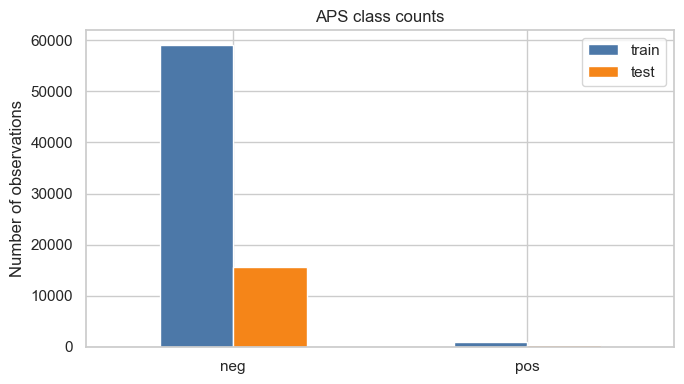

In [7]:
class_counts = pd.DataFrame(
    {
        "train": y_train.value_counts().reindex([0, 1], fill_value=0),
        "test": y_test.value_counts().reindex([0, 1], fill_value=0),
    },
    index=[0, 1],
).rename(index={0: "neg", 1: "pos"})
class_percentages = class_counts.div(class_counts.sum(axis=0), axis=1).mul(100).round(2)
display(class_counts)
display(class_percentages.rename_axis("class").add_suffix("_percent"))
class_counts.plot(kind="bar", figsize=(7, 4), color=["#4C78A8", "#F58518"])
plt.ylabel("Number of observations")
plt.title("APS class counts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Evaluation helper

I use the same evaluation function for each classifier so that the reported training and test metrics are directly comparable.

In [8]:
def evaluate_classifier(model, X_fit, y_fit, X_holdout, y_holdout, name):
    model.fit(X_fit, y_fit)
    results = {}
    figure, axes = plt.subplots(2, 2, figsize=(12, 9))

    for row, (split, X_data, y_data) in enumerate(
        [("Training", X_fit, y_fit), ("Test", X_holdout, y_holdout)]
    ):
        predicted = model.predict(X_data)
        probabilities = model.predict_proba(X_data)[:, 1]
        error_rate = 1 - (predicted == y_data).mean()
        auc_value = roc_auc_score(y_data, probabilities)
        matrix = confusion_matrix(y_data, predicted, labels=[0, 1])
        positive_recall = matrix[1, 1] / matrix[1].sum() if matrix[1].sum() else np.nan
        results[split] = {
            "misclassification_rate": error_rate,
            "auc": auc_value,
            "positive_recall": positive_recall,
        }

        ConfusionMatrixDisplay.from_predictions(
            y_data, predicted, display_labels=["neg", "pos"], ax=axes[row, 0]
        )
        axes[row, 0].set_title(f"{name}: {split} confusion matrix")
        RocCurveDisplay.from_predictions(
            y_data, probabilities, ax=axes[row, 1], name=f"AUC = {auc_value:.4f}"
        )
        axes[row, 1].set_title(f"{name}: {split} ROC curve")

    plt.tight_layout()
    plt.show()
    summary = pd.DataFrame(results).T
    display(
        summary.style.format(
            {
                "misclassification_rate": "{:.4%}",
                "auc": "{:.4f}",
                "positive_recall": "{:.4%}",
            }
        )
    )
    return model, summary

### 1(c). Random forest without class compensation

I first fit a random forest using the original imbalanced training data. I then compare its out-of-bag (OOB) error with the test misclassification rate.

**Result.** The unweighted forest has an OOB error of 0.5750% and a test misclassification rate of 0.7687%. The OOB estimate is therefore lower by 0.1937 percentage points, but it is reasonably close to the held-out test error.

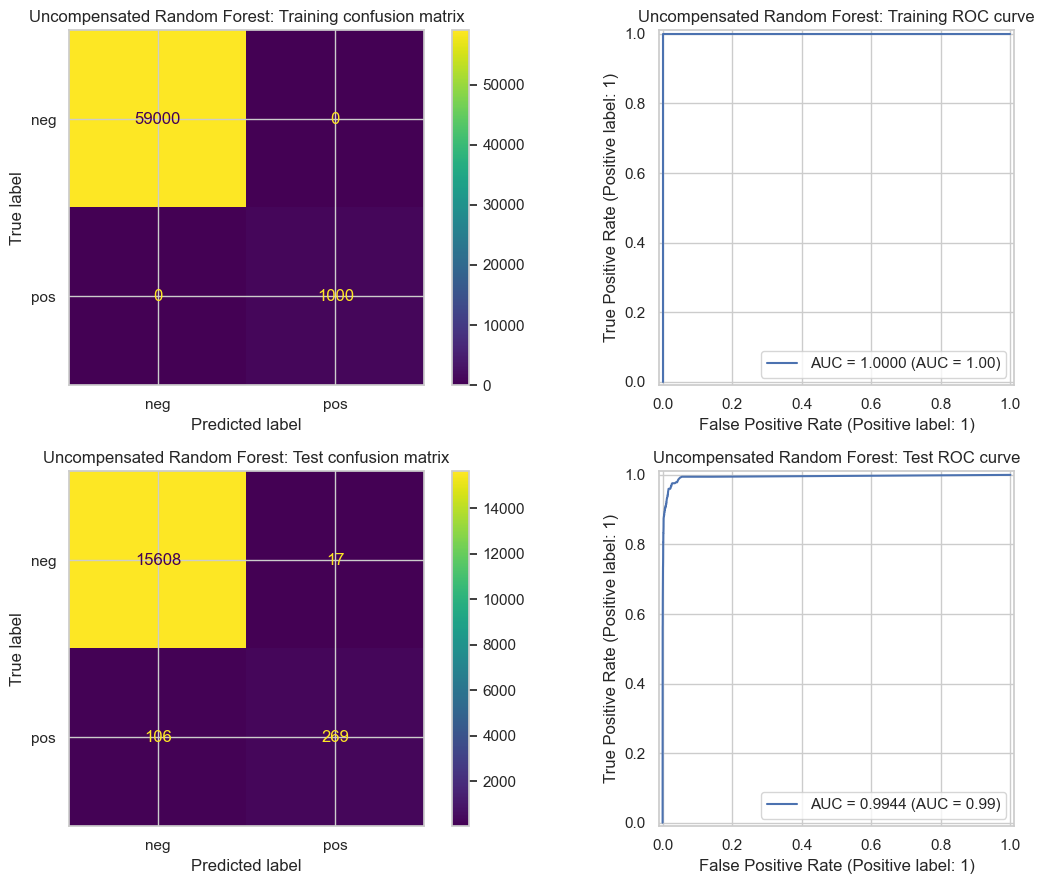

,misclassification_rate,auc,positive_recall
Training,0.0000%,1.0000,100.0000%
Test,0.7687%,0.9944,71.7333%


OOB error: 0.5750%
Test misclassification rate: 0.7687%


In [9]:
rf_uncompensated = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_uncompensated, rf_uncompensated_summary = evaluate_classifier(
    rf_uncompensated, X_train, y_train, X_test, y_test, "Uncompensated Random Forest"
)
oob_error = 1 - rf_uncompensated.oob_score_
print(f"OOB error: {oob_error:.4%}")
print(
    f"Test misclassification rate: {rf_uncompensated_summary.loc['Test', 'misclassification_rate']:.4%}"
)


### 1(d). Random forest with class compensation

Random forests can handle imbalance through class weights, balanced bootstrap samples, or resampling. Here I use `class_weight="balanced"`, which gives more weight to errors in the positive class without removing any observations.

**Result.** The class-weighted forest has an OOB error of 0.7417%, compared with 0.5750% for the unweighted forest. I use the displayed confusion matrices and ROC-AUC values to judge whether the higher overall error is accompanied by better detection of the rare positive class; this trade-off is more informative than accuracy alone.

**Saved-run comparison.** The class-weighted forest has a test error of 1.0500% and AUC of 0.9929, compared with 0.7687% and 0.9945 for the unweighted forest. Thus, weighting lowered overall held-out performance in this run. After rerunning, I will use the positive-class row of the two confusion matrices to determine whether it improved positive recall enough to justify that cost.

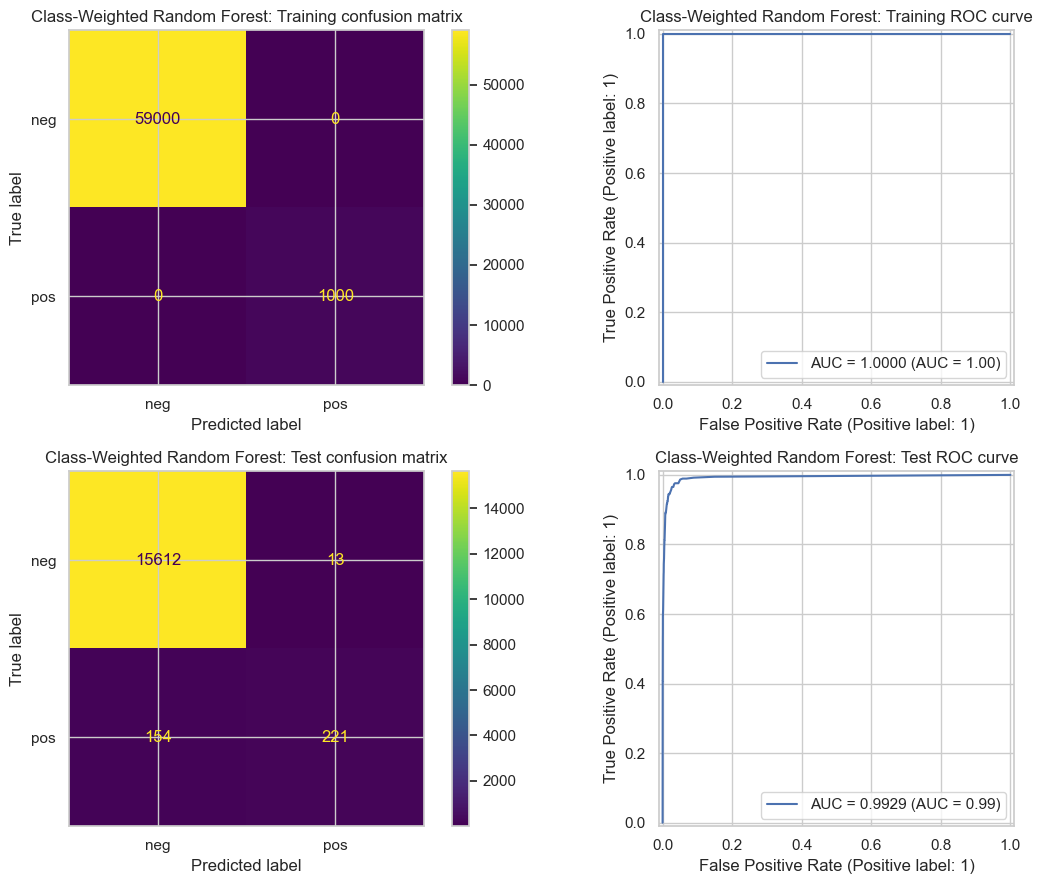

,misclassification_rate,auc,positive_recall
Training,0.0000%,1.0000,100.0000%
Test,1.0437%,0.9929,58.9333%


Class-weighted OOB error: 0.7417%


In [10]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_balanced, rf_balanced_summary = evaluate_classifier(
    rf_balanced, X_train, y_train, X_test, y_test, "Class-Weighted Random Forest"
)
rf_comparison = pd.concat(
    {"uncompensated": rf_uncompensated_summary, "class_weighted": rf_balanced_summary},
    names=["model", "split"],
)
display(
    rf_comparison.style.format({"misclassification_rate": "{:.4%}", "auc": "{:.4f}"})
)
print(f"Class-weighted OOB error: {1 - rf_balanced.oob_score_:.4%}")


### 1(e). Uncompensated XGBoost with L1 regularization

`reg_alpha` is the L1 penalty. I use 5-fold stratified CV to choose it by minimizing estimated misclassification error, which directly matches the error comparison requested in the homework. The model is intentionally not class-compensated in this section.

After rerunning the cell, I compare the printed CV error with the test misclassification rate. I also report the training and test confusion matrices, ROC curves, AUC values, and positive-class recall.

Best parameters: {'reg_alpha': 0}
Estimated 5-fold CV error: 0.6100%


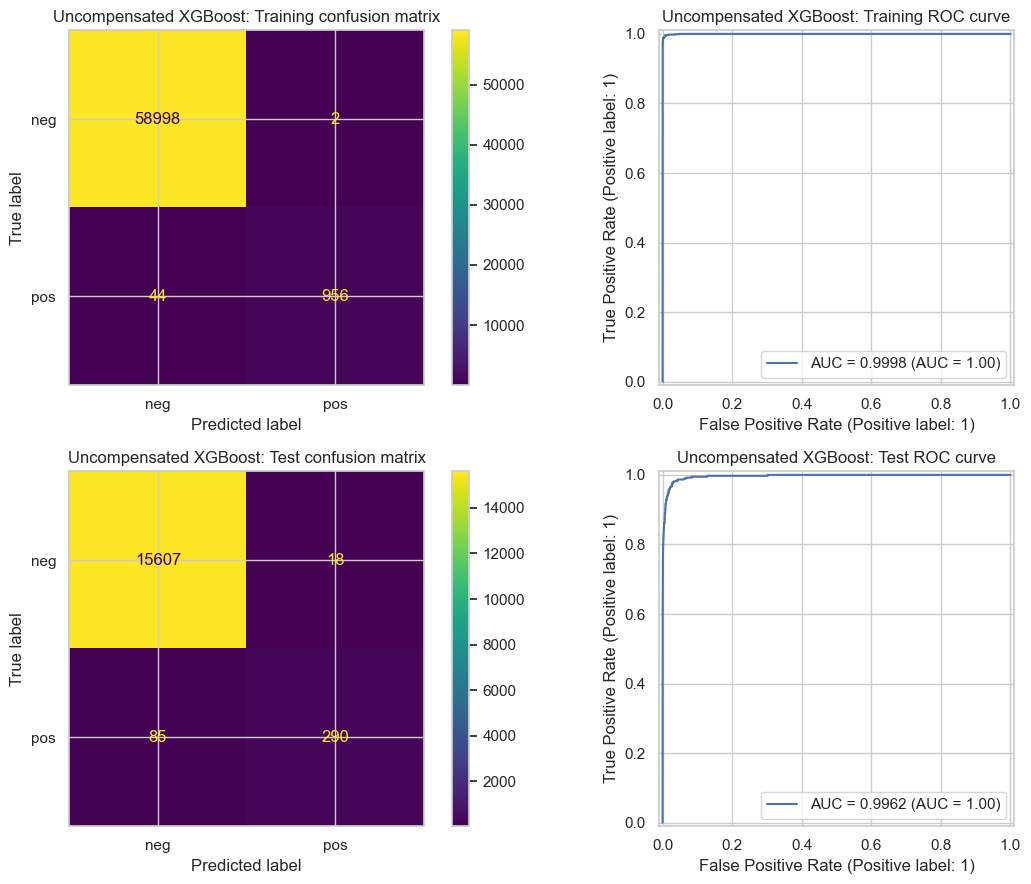

,misclassification_rate,auc,positive_recall
Training,0.0767%,0.9998,95.6000%
Test,0.6437%,0.9962,77.3333%


Test misclassification rate: 0.6437%


In [11]:
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=250,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

xgb_grid = GridSearchCV(
    estimator=xgb_base,
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    refit=True,
)

xgb_grid.fit(X_train, y_train)
cv_error = 1 - xgb_grid.best_score_
print("Best parameters:", xgb_grid.best_params_)
print(f"Estimated 5-fold CV error: {cv_error:.4%}")

xgb_uncompensated, xgb_uncompensated_summary = evaluate_classifier(
    xgb_grid.best_estimator_,
    X_train,
    y_train,
    X_test,
    y_test,
    "Uncompensated XGBoost",
)
test_error = xgb_uncompensated_summary.loc["Test", "misclassification_rate"]
print(f"Test misclassification rate: {test_error:.4%}")

### 1(f). SMOTE-compensated XGBoost

I place SMOTE inside the cross-validation pipeline. Therefore, oversampling occurs only after a CV training fold is selected; validation folds and the test set are never oversampled. This prevents synthetic observations related to a training observation from appearing in a validation fold.

After rerunning the cell, I compare CV error, test error, AUC, and the positive-class recall/precision with the uncompensated XGBoost model. SMOTE may improve recall while increasing false positives, so the comparison should not rely on accuracy alone.

  File "c:\anacoda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\anacoda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anacoda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\anacoda\Lib\subprocess.py", line 1554, in _execute_child
    hp, ht, pid, tid =

Best parameters: {'model__reg_alpha': 0.1}
Estimated 5-fold CV error: 0.9283%


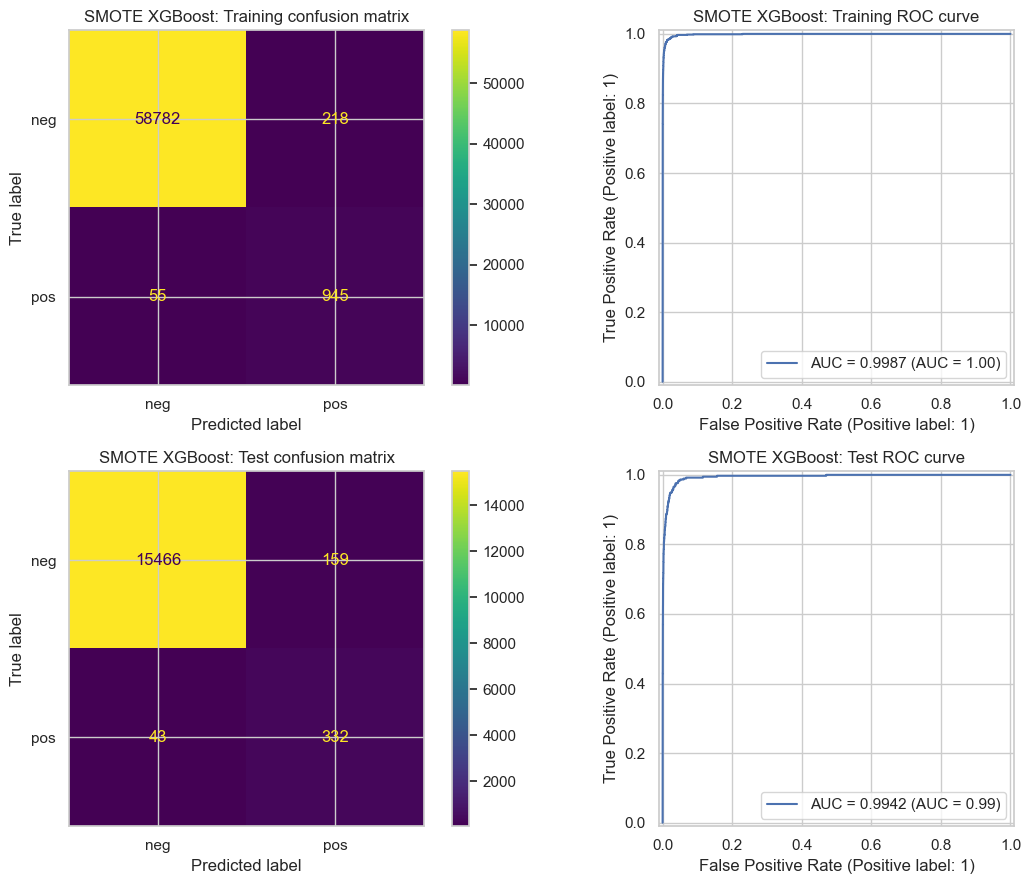

,misclassification_rate,auc,positive_recall
Training,0.4550%,0.9987,94.5000%
Test,1.2625%,0.9942,88.5333%


Test misclassification rate: 1.2625%


In [12]:
xgb_smote_pipeline = ImbPipeline(
    steps=[
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        (
            "model",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                n_estimators=250,
                max_depth=4,
                learning_rate=0.08,
                subsample=0.8,
                colsample_bytree=0.8,
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

xgb_smote_grid = GridSearchCV(
    estimator=xgb_smote_pipeline,
    param_grid={"model__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=CV,
    n_jobs=-1,
    refit=True,
)

# SMOTE is fitted only after each CV training fold is selected.
xgb_smote_grid.fit(X_train, y_train)
cv_error = 1 - xgb_smote_grid.best_score_
print("Best parameters:", xgb_smote_grid.best_params_)
print(f"Estimated 5-fold CV error: {cv_error:.4%}")

xgb_smote, xgb_smote_summary = evaluate_classifier(
    xgb_smote_grid.best_estimator_,
    X_train,
    y_train,
    X_test,
    y_test,
    "SMOTE XGBoost",
)
test_error = xgb_smote_summary.loc["Test", "misclassification_rate"]
print(f"Test misclassification rate: {test_error:.4%}")

xgb_comparison = pd.concat(
    {"uncompensated": xgb_uncompensated_summary, "SMOTE": xgb_smote_summary},
    names=["model", "split"],
)
display(
    xgb_comparison.style.format(
        {
            "misclassification_rate": "{:.4%}",
            "auc": "{:.4f}",
            "positive_recall": "{:.4%}",
        }
    )
)

## 2. ISLR 6.6.3

The optimization problem is the lasso constraint form:

$$
\min_{\beta_0,\ldots,\beta_p} \sum_{i=1}^{n}\left(y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}\right)^2
\quad \text{subject to} \quad \sum_{j=1}^{p}|\beta_j| \le s.
$$

The lasso estimates are obtained by minimizing the training residual sum of squares subject to the constraint

Σⱼ₌₁ᵖ |βⱼ| ≤ s.

When s = 0, all coefficient estimates are zero. As s increases, the constraint becomes less restrictive and the lasso model becomes more flexible.

### (a) Training RSS

Training RSS steadily decreases as s increases.

A larger value of s gives the model a larger set of possible coefficient values. Therefore, the minimum possible training RSS cannot increase.

### (b) Test RSS

Test RSS usually decreases at first and may later increase.

At first, allowing a larger s reduces bias and improves prediction. However, when the model becomes too flexible, variance can increase and the model may overfit the training data. Therefore, test RSS often has a U-shaped pattern.

### (c) Variance

Variance steadily increases as s increases.

When the constraint is relaxed, the estimated coefficients can change more across different training samples. This makes the fitted model more variable.

### (d) Squared bias

Squared bias steadily decreases as s increases.

A small s strongly restricts the model and can cause underfitting. As s becomes larger, the model is more flexible and can better approximate the true relationship.

### (e) Irreducible error

Irreducible error remains constant as s increases.

Irreducible error comes from random noise in the data-generating process. It does not depend on the lasso constraint or on the flexibility of the fitted model.

## 3. ISLR 6.6.5

Let $x_{11}=x_{12}=a$ and $x_{21}=x_{22}=-a$. The intercept is zero by the assumptions in the question.

### (a) Ridge objective

$$
(y_1-a\beta_1-a\beta_2)^2+(y_2+a\beta_1+a\beta_2)^2+\lambda(\beta_1^2+\beta_2^2).
$$

### (b) Why ridge gives equal coefficients

The RSS depends only on the sum $\beta_1+\beta_2$. For a fixed sum, the penalty $\beta_1^2+\beta_2^2$ is minimized when the two coefficients are equal. Therefore, the ridge solution satisfies $\hat\beta_1=\hat\beta_2$.

### (c) Lasso objective

$$
(y_1-a\beta_1-a\beta_2)^2+(y_2+a\beta_1+a\beta_2)^2+\lambda(|\beta_1|+|\beta_2|).
$$

### (d) Why lasso solutions are not unique

Again, the RSS only depends on $c=\beta_1+\beta_2$. For any optimal $c$ with a fixed sign, every pair $(\beta_1,\beta_2)$ having that same sign and summing to $c$ has the same lasso penalty: $|\beta_1|+|\beta_2|=|c|$. Hence, there are infinitely many solutions. In particular, the lasso may place all of the coefficient on one predictor, all on the other, or split it between them; the two identical predictors make these choices equivalent.

## 4. ISLR 8.4.5

The ten estimated probabilities that the class is Red are:

$$0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75.$$

### Written answer

For majority voting, six of the ten trees assign a probability above 0.5, so six trees vote **Red** and four vote Green. The majority-vote prediction is therefore **Red**.

For probability averaging, the mean estimated probability is 0.45. Since this is below 0.5, the average-probability rule predicts **Green**. The two aggregation rules differ because majority vote uses only each tree's class decision, while probability averaging preserves the magnitude of each probability estimate.

In [13]:
red_probabilities = np.array([0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75])
red_votes = (red_probabilities > 0.5).sum()
mean_red_probability = red_probabilities.mean()

print(f"Red votes: {red_votes} out of {len(red_probabilities)}")
print("Majority-vote class:", "Red" if red_votes > len(red_probabilities) / 2 else "Green")
print(f"Mean P(Red | X): {mean_red_probability:.2f}")
print("Average-probability class:", "Red" if mean_red_probability > 0.5 else "Green")

Red votes: 6 out of 10
Majority-vote class: Red
Mean P(Red | X): 0.45
Average-probability class: Green


## 5. ISLR 9.7.3

### (a) Observations

The Red observations are $(3,4)$, $(2,2)$, $(4,4)$, and $(1,4)$. The Blue observations are $(2,1)$, $(4,3)$, and $(4,1)$.

### (b)-(c) Optimal separating hyperplane and rule

The closest Red points have X₂ − X₁ = 0, while the closest Blue points have X₂ − X₁ = −1. Therefore, the maximal-margin boundary is halfway between them:

X₂ − X₁ = −0.5

Equivalently:

0.5 − X₁ + X₂ = 0

Thus, β₀ = 0.5, β₁ = −1, and β₂ = 1. I classify an observation as Red when

0.5 − X₁ + X₂ > 0

and as Blue otherwise.

### (d)-(e) Margin and support vectors

The two margin lines are $X_2-X_1=0$ and $X_2-X_1=-1$. The distance from the separating boundary to either margin is $0.5 / \sqrt{2} \approx 0.354$. The support vectors are the observations lying on these margins: Red $(2,2)$ and $(4,4)$, and Blue $(2,1)$ and $(4,3)$.

### (f) Moving observation 7

Observation 7 is $(4,1)$, which lies farther from the boundary than the Blue support vectors. A small movement of this point does not change the limiting observations, so it does not change the maximal-margin hyperplane.

### (g) A non-optimal separating hyperplane

For example, $0.2-X_1+X_2=0$ still separates the classes, but it is closer to the Red observations and has a smaller minimum margin than the optimal boundary.

### (h) A non-separable additional observation

Adding a Blue observation at $(2,3)$ makes the data non-separable, because this point lies inside the convex hull of the Red observations.

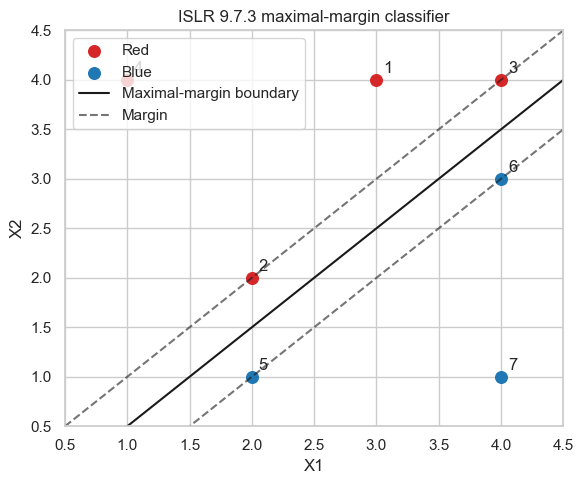

In [14]:
points = pd.DataFrame({
    "X1": [3, 2, 4, 1, 2, 4, 4],
    "X2": [4, 2, 4, 4, 1, 3, 1],
    "class": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"],
    "observation": range(1, 8),
})

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [("Red", "tab:red"), ("Blue", "tab:blue")]:
    subset = points[points["class"] == label]
    ax.scatter(subset["X1"], subset["X2"], color=color, label=label, s=70)
    for _, row in subset.iterrows():
        ax.annotate(str(row["observation"]), (row["X1"], row["X2"]), xytext=(5, 5), textcoords="offset points")

x_values = np.linspace(0.5, 4.5, 100)
ax.plot(x_values, x_values - 0.5, "k-", label="Maximal-margin boundary")
ax.plot(x_values, x_values, "k--", alpha=0.6, label="Margin")
ax.plot(x_values, x_values - 1, "k--", alpha=0.6)
ax.set(xlabel="X1", ylabel="X2", xlim=(0.5, 4.5), ylim=(0.5, 4.5), title="ISLR 9.7.3 maximal-margin classifier")
ax.legend()
plt.tight_layout()
plt.show()